# Лабораторная работа №1. Аналитика данных на Python

На примере с датасетом такси.

## 0. Импорт необходимых библиотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

## 1. Чтение файла и работа с датасетом

In [2]:
import gdown

gdown.download('https://drive.google.com/uc?id=1P08K885c5M81d7EuWQeHv_OfPuW-bnO_', 'taxi.csv', quiet=False)

df_taxi = pd.read_csv('taxi.csv')
print('Размер датасета:', df_taxi.shape)
df_taxi.head()

Downloading...
From: https://drive.google.com/uc?id=1P08K885c5M81d7EuWQeHv_OfPuW-bnO_
To: c:\Users\Алексей\Desktop\Учёба\ОАД, ТХБД, нейросети и pandas\Технологии хранения больших данных\big-data-course\Лабораторные\Лаба 1\taxi.csv
100%|██████████| 13.4M/13.4M [00:59<00:00, 224kB/s]

Размер датасета: (100000, 11)


,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2863541,2,2016-01-31 13:12:20,2016-01-31 13:21:37,2,-73.989609,40.741718,-73.991013,40.755867,N,557
1,id1752141,1,2016-05-03 18:20:59,2016-05-03 18:41:09,1,-73.993935,40.761517,-73.975281,40.751507,N,1210
2,id1331142,1,2016-06-05 02:20:39,2016-06-05 02:28:04,1,-73.988625,40.722538,-73.980347,40.742752,N,445
3,id0227018,2,2016-01-11 20:07:13,2016-01-11 20:14:26,1,-73.976723,40.775311,-73.964333,40.765560,N,433
4,id2263790,2,2016-01-22 00:31:59,2016-01-22 00:40:48,5,-74.005852,40.740360,-73.988708,40.758781,N,529


In [3]:
df_taxi.info()
df_taxi.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 11 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   id                  100000 non-null  object 
 1   vendor_id           100000 non-null  int64  
 2   pickup_datetime     100000 non-null  object 
 3   dropoff_datetime    100000 non-null  object 
 4   passenger_count     100000 non-null  int64  
 5   pickup_longitude    100000 non-null  float64
 6   pickup_latitude     100000 non-null  float64
 7   dropoff_longitude   100000 non-null  float64
 8   dropoff_latitude    100000 non-null  float64
 9   store_and_fwd_flag  100000 non-null  object 
 10  trip_duration       100000 non-null  int64  
dtypes: float64(4), int64(3), object(4)
memory usage: 8.4+ MB


,vendor_id,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,1.533810,1.667470,-73.973511,40.750940,-73.973475,40.751800,948.992000
std,0.498858,1.318139,0.038094,0.028180,0.036092,0.032391,3154.520022
min,1.000000,0.000000,-74.421059,40.506294,-74.421059,40.508598,2.000000
25%,1.000000,1.000000,-73.991806,40.737384,-73.991379,40.735797,396.000000
50%,2.000000,1.000000,-73.981674,40.754147,-73.979858,40.754416,660.000000
75%,2.000000,2.000000,-73.967415,40.768314,-73.963326,40.769657,1072.000000
max,2.000000,6.000000,-73.446007,41.292198,-72.720734,41.292198,86379.000000


Колонка времени: pickup_datetime
Всего поездок за выходные: 28411

Количество поездок за выходные по месяцам:
pickup_datetime
1    4610
2    4650
3    4694
4    5279
5    4977
6    4201
Name: count, dtype: int64


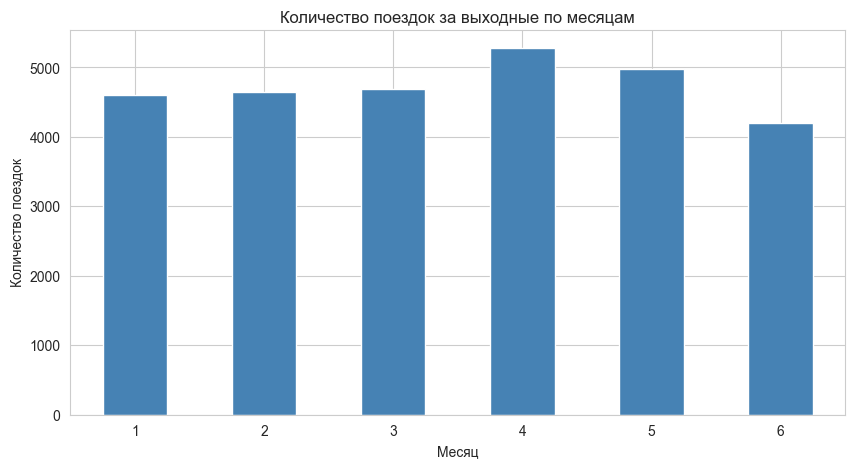

In [4]:
# Ищем колонку с датой/временем
time_col = None
for col in df_taxi.columns:
    if any(k in col.lower() for k in ['pickup', 'time', 'date']):
        try:
            df_taxi[col] = pd.to_datetime(df_taxi[col])
            time_col = col
            break
        except Exception:
            pass

print('Колонка времени:', time_col)
assert time_col is not None, 'Не найдена колонка с датой/временем'

# Фильтрация поездок только за выходные (5 = суббота, 6 = воскресенье)
df_taxi['dayofweek'] = df_taxi[time_col].dt.dayofweek
df_weekend = df_taxi[df_taxi['dayofweek'].isin([5, 6])].copy()
print('Всего поездок за выходные:', len(df_weekend))

# Общее количество поездок по месяцам (за выходные)
trips_by_month = df_weekend[time_col].dt.month.value_counts().sort_index()
print('\nКоличество поездок за выходные по месяцам:')
print(trips_by_month)

# Наглядная визуализация
trips_by_month.plot(kind='bar', figsize=(10, 5), color='steelblue')
plt.title('Количество поездок за выходные по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Количество поездок')
plt.xticks(rotation=0)
plt.show()

Используется gdown для скачивания по id из Google Drive. Колонка с датой ищется автоматически (по подстрокам pickup/time/date), чтобы код был устойчив к разным версиям датасета.

## 2. Создание df

In [5]:
np.random.seed(42)
n = 10000
chars = '1234567890abcdefghighk'

def generate_user_id():
    return ''.join(np.random.choice(list(chars), size=15))

user_ids = [generate_user_id() for _ in range(n)]

df = pd.DataFrame({
    'user_id': user_ids,
    'order_number': np.random.randint(1, 11, size=n),
    'delivery_time': np.random.normal(loc=1440, scale=200, size=n),
    'total_cost': np.random.exponential(scale=1.0, size=n) + 1,
    'retention': np.random.choice([1, 2, 3, 4, 5], size=n, p=[0.35, 0.25, 0.2, 0.15, 0.05])
})

print('Размер до удаления дублей:', df.shape)
df = df.drop_duplicates(subset='user_id', keep='first').reset_index(drop=True)
print('Размер после удаления дублей:', df.shape)
df.head()

Размер до удаления дублей: (10000, 5)
Размер после удаления дублей: (10000, 5)


,user_id,order_number,delivery_time,total_cost,retention
0,7gea8h7iaah483k,8,1446.062698,1.220073,4
1,h2b62h1bkbg0fee,1,1482.079506,1.576198,1
2,ibg35i7h97h4dh9,9,1324.140326,1.349728,1
3,h2ge7b8e3dg4h84,4,1503.353793,1.527056,3
4,26k04khb204dfe8,8,1632.910315,1.274532,1


In [6]:
# Проверка распределений
df.describe()

,order_number,delivery_time,total_cost,retention
count,10000.000000,10000.000000,10000.000000,10000.000000
mean,5.484600,1439.818371,1.981354,2.299000
std,2.878192,199.366784,0.986084,1.228719
min,1.000000,682.259841,1.000002,1.000000
25%,3.000000,1306.199797,1.282479,1.000000
50%,5.000000,1436.581151,1.674332,2.000000
75%,8.000000,1574.269232,2.343517,3.000000
max,10.000000,2177.895595,10.653499,5.000000


Генерация df: np.random.seed(42) для воспроизводимости; retention — через np.random.choice с заданными вероятностями; total_cost - exponential(scale=1) + 1 (лямбда = 1, смещение +1).

## 3. Дополнение df

In [7]:
# Среднее время доставки по группе (по номеру заказа) для каждой строки
df['avg_delivery_by_order'] = df.groupby('order_number')['delivery_time'].transform('mean')

# Сегмент по номеру заказа: диапазоны по 3
def get_segment(order):
    start = ((order - 1) // 3) * 3 + 1
    end = start + 2
    return f'{start}-{end}'

df['segment'] = df['order_number'].apply(get_segment)

print(df[['order_number', 'avg_delivery_by_order', 'segment']]
      .drop_duplicates()
      .sort_values('order_number')
      .to_string(index=False))

 order_number  avg_delivery_by_order segment
            1            1444.160220     1-3
            2            1442.164017     1-3
            3            1442.220374     1-3
            4            1428.119111     4-6
            5            1442.572524     4-6
            6            1440.675051     4-6
            7            1438.504247     7-9
            8            1443.620680     7-9
            9            1442.722991     7-9
           10            1433.511904   10-12


Сегменты: ((order - 1) // 3) * 3 + 1 даёт начала диапазонов 1, 4, 7, 10, конец — start + 2.

## 4. Исследование df

In [8]:
cost = df['total_cost']
print('Мода:', cost.mode().values)
print('Медиана:', cost.median())
print('Среднее:', cost.mean())
print('Дисперсия:', cost.var())
print('Стандартное отклонение:', cost.std())

Мода: [ 1.00000228  1.00001577  1.00008059 ...  9.24528981  9.37645233
 10.65349913]
Медиана: 1.6743315432395691
Среднее: 1.981353827123727
Дисперсия: 0.9723624463528443
Стандартное отклонение: 0.9860844012318846


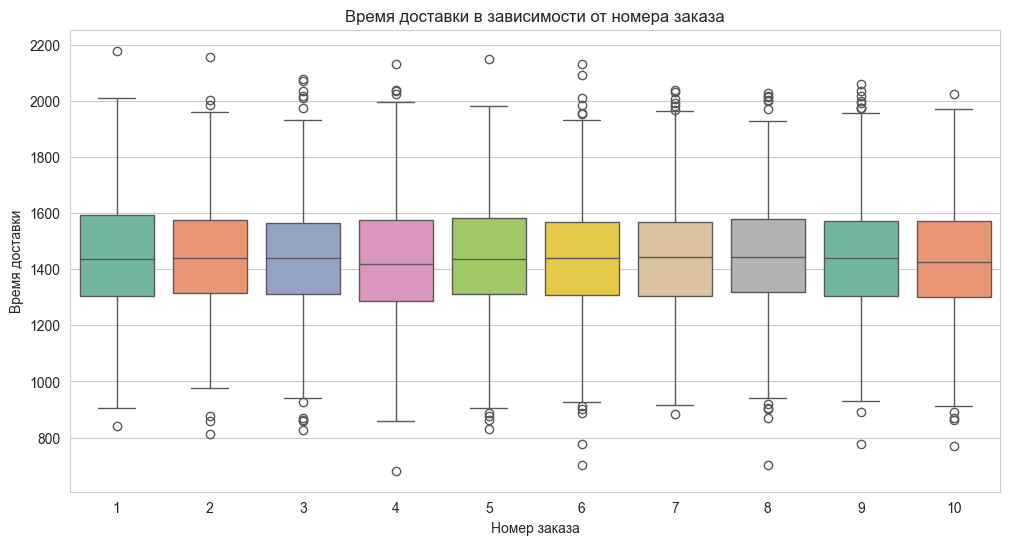

In [9]:
# График, наиболее полно описывающий время доставки в зависимости от номера заказа
plt.figure(figsize=(12, 6))
sns.boxplot(x='order_number', y='delivery_time', data=df, palette='Set2')
plt.title('Время доставки в зависимости от номера заказа')
plt.xlabel('Номер заказа')
plt.ylabel('Время доставки')
plt.show()

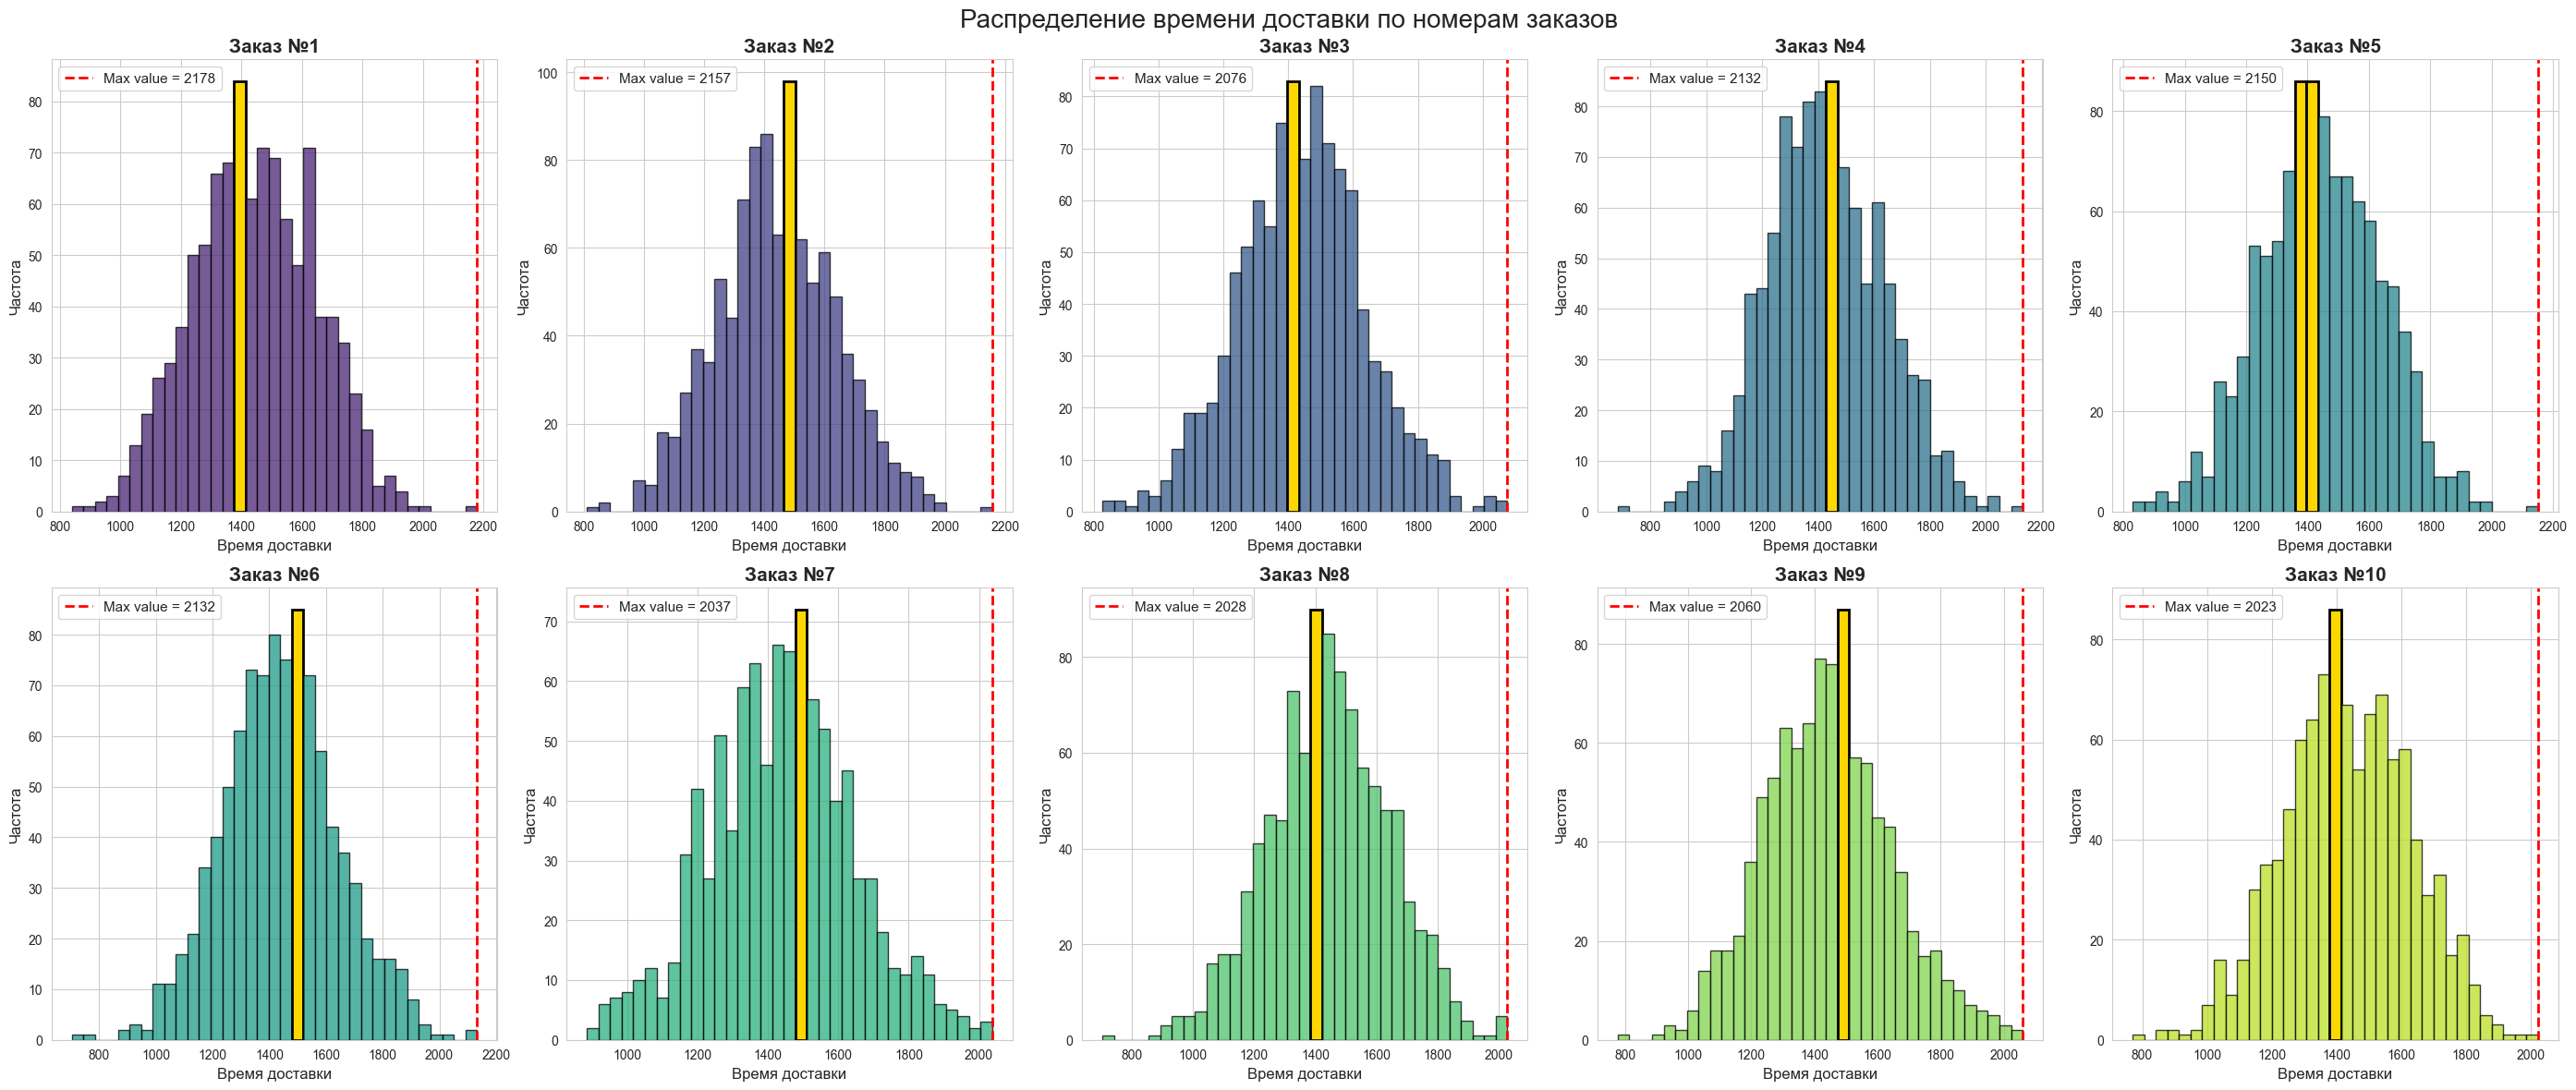

In [ ]:
# Матрица графиков распределения времени доставки по каждому номеру заказа
fig, axes = plt.subplots(2, 5, figsize=(28, 12))
colors = plt.cm.viridis(np.linspace(0.1, 0.9, 10))

for i, order in enumerate(range(1, 11)):
    ax = axes[i // 5, i % 5]
    data = df[df['order_number'] == order]['delivery_time']

    # частоты, границы, сами столбцы
    counts, bins, patches = ax.hist(data, bins=35, color=colors[i], alpha=0.75, edgecolor='black')

    max_count = max(counts)

    for count, patch in zip(counts, patches):
        if count == max_count:
            patch.set_facecolor('gold')  # Выделяем цветом
            patch.set_alpha(1.0)         # Делаем непрозрачным
            patch.set_linewidth(2)       # Делаем обводку чуть толще

    # Пунктирная линия для максимального значения времени
    ax.axvline(data.max(), color='red', linestyle='--', linewidth=2,
               label=f'Max value = {data.max():.0f}')

    ax.set_title(f'Заказ №{order}', fontsize=15, fontweight='bold')
    ax.set_xlabel('Время доставки', fontsize=12)
    ax.set_ylabel('Частота', fontsize=12)
    ax.legend(fontsize=11)

plt.suptitle('Распределение времени доставки по номерам заказов', fontsize=20)
plt.tight_layout()
plt.show()

## 5. Кластеризация

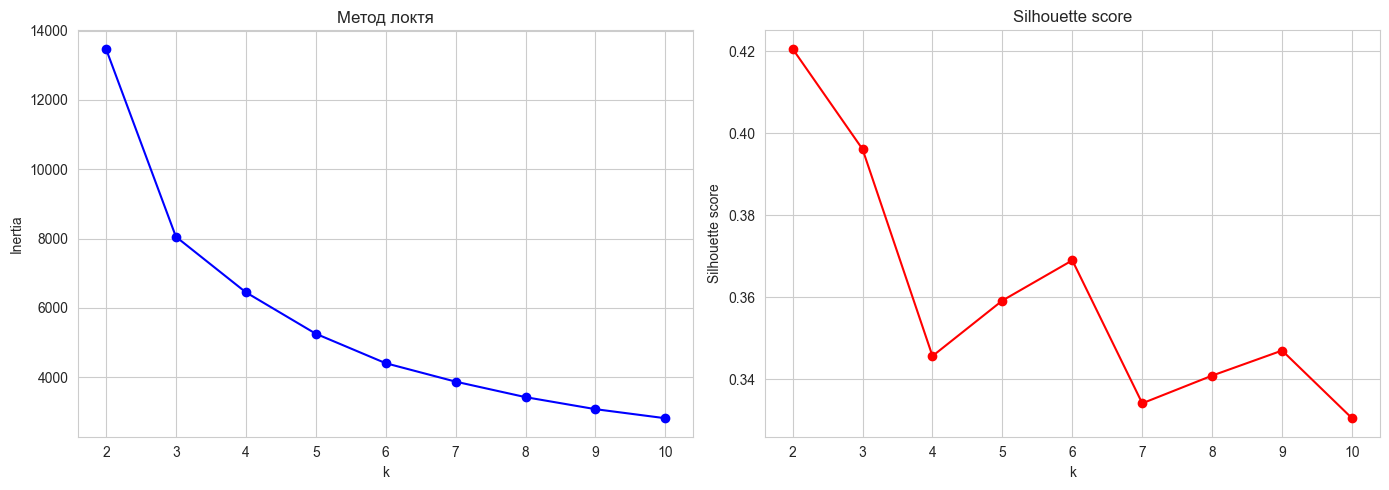

k = 2: silhouette = 0.4206, inertia = 13476.49
k = 3: silhouette = 0.3961, inertia = 8052.73
k = 4: silhouette = 0.3456, inertia = 6449.86
k = 5: silhouette = 0.3592, inertia = 5254.24
k = 6: silhouette = 0.3690, inertia = 4403.63
k = 7: silhouette = 0.3341, inertia = 3871.56
k = 8: silhouette = 0.3408, inertia = 3424.08
k = 9: silhouette = 0.3469, inertia = 3077.03
k = 10: silhouette = 0.3304, inertia = 2815.20


In [20]:
X = df[['delivery_time', 'total_cost']].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

inertias = []
sil_scores = []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(list(K_range), inertias, 'bo-')
axes[0].set_xlabel('k')
axes[0].set_ylabel('Inertia')
axes[0].set_title('Метод локтя')

axes[1].plot(list(K_range), sil_scores, 'ro-')
axes[1].set_xlabel('k')
axes[1].set_ylabel('Silhouette score')
axes[1].set_title('Silhouette score')
plt.tight_layout()
plt.show()

for k, s in zip(K_range, sil_scores):
    print(f'k = {k}: silhouette = {s:.4f}, inertia = {inertias[k-2]:.2f}')

In [29]:
# Обоснование: выбираем k=3 (наблюдается «локоть» на графике инерции, а также
# k=4 - это провал по метрике Silhouette; после 3-его кластера добавление новых центров дает всё
# меньший и меньший выигрыш в компактности.)
# Выбор 3 кластеров дает хороший баланс между методом локтя и качеством разделения.
optimal_k = 3
km_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df['cluster'] = km_final.fit_predict(X_scaled)

print('Размеры кластеров:')
print(df['cluster'].value_counts().sort_index())
print('\nСредние значения по кластерам:')
print(df.groupby('cluster')[['delivery_time', 'total_cost']].mean().round(2))

Размеры кластеров:
cluster
0    1536
1    4397
2    4067
Name: count, dtype: int64

Средние значения по кластерам:
         delivery_time  total_cost
cluster                           
0              1431.43        3.81
1              1284.40        1.65
2              1611.02        1.65


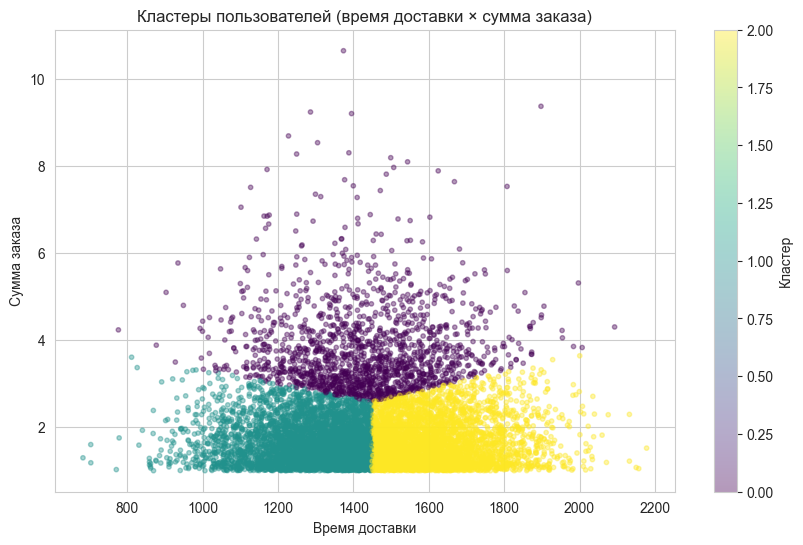

In [30]:
plt.figure(figsize=(10, 6))
scatter = plt.scatter(df['delivery_time'], df['total_cost'],
                      c=df['cluster'], cmap='viridis', alpha=0.4, s=10)
plt.colorbar(scatter, label='Кластер')
plt.xlabel('Время доставки')
plt.ylabel('Сумма заказа')
plt.title('Кластеры пользователей (время доставки × сумма заказа)')
plt.show()

Кластеризация: признаки стандартизированы (StandardScaler), число кластеров выбрано по «локтю» инерции и silhouette_score (в коде — k = 3; при желании можно поменять optimal_k).

## 6. A/B анализ

In [31]:
# Сравниваем два кластера: 0 и 1
cluster_a = df[df['cluster'] == 0]
cluster_b = df[df['cluster'] == 1]

print(f'Кластер A (0): n = {len(cluster_a)}')
print(f'Кластер B (1): n = {len(cluster_b)}\n')

metrics = ['delivery_time', 'total_cost', 'retention']
for m in metrics:
    a, b = cluster_a[m], cluster_b[m]

    res = stats.ttest_ind(a, b, equal_var=False)
    if hasattr(res, 'pvalue'):          # scipy >= 1.11
        t_stat, p_val = res.statistic, res.pvalue
    else:                               # scipy < 1.11
        t_stat, p_val = res[0], res[1]

    # на всякий случай приводим к float
    p_val = float(p_val)

    print(f'--- {m} ---')
    print(f'  Среднее A: {a.mean():.4f} | Среднее B: {b.mean():.4f}')
    print(f'  t-статистика: {t_stat:.4f}, p-value: {p_val:.4f}')
    if p_val < 0.05:
        print('  Вывод: различия статистически значимы (p < 0.05)')
    else:
        print('  Вывод: различия статистически не значимы (p >= 0.05)')
    print()

Кластер A (0): n = 1536
Кластер B (1): n = 4397

--- delivery_time ---
  Среднее A: 1431.4254 | Среднее B: 1284.3969
  t-статистика: 30.9271, p-value: 0.0000
  Вывод: различия статистически значимы (p < 0.05)

--- total_cost ---
  Среднее A: 3.8145 | Среднее B: 1.6453
  t-статистика: 81.5213, p-value: 0.0000
  Вывод: различия статистически значимы (p < 0.05)

--- retention ---
  Среднее A: 2.2520 | Среднее B: 2.3059
  t-статистика: -1.4745, p-value: 0.1405
  Вывод: различия статистически не значимы (p >= 0.05)



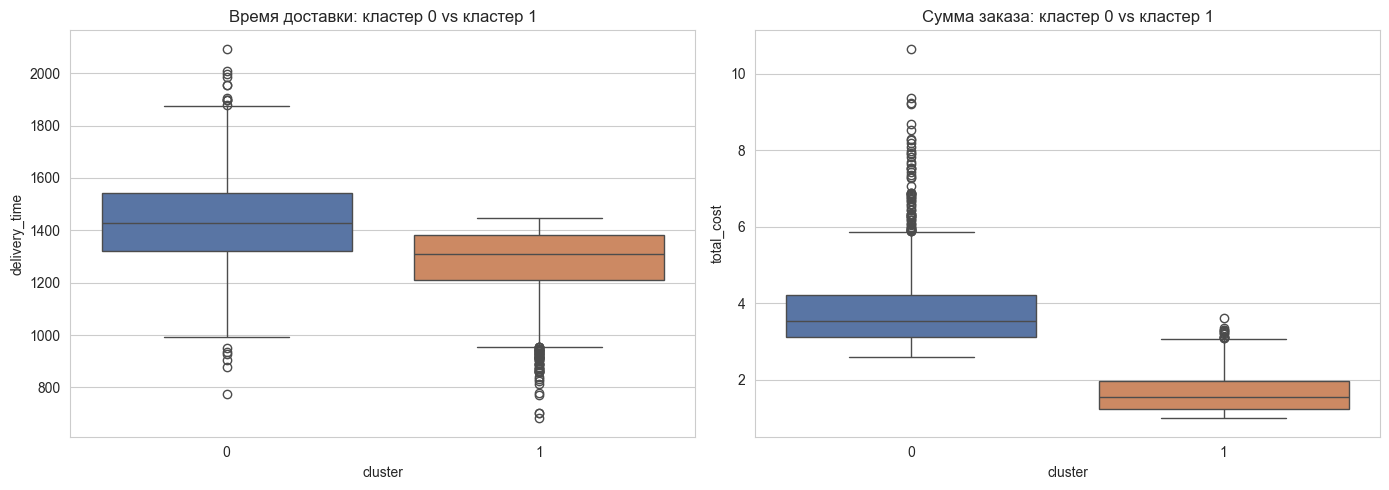

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(x='cluster', y='delivery_time', data=df[df['cluster'].isin([0, 1])],
            ax=axes[0], palette=['#4C72B0', '#DD8452'])
axes[0].set_title('Время доставки: кластер 0 vs кластер 1')

sns.boxplot(x='cluster', y='total_cost', data=df[df['cluster'].isin([0, 1])],
            ax=axes[1], palette=['#4C72B0', '#DD8452'])
axes[1].set_title('Сумма заказа: кластер 0 vs кластер 1')

plt.tight_layout()
plt.show()

A/B: используется scipy.stats.ttest_ind(..., equal_var=False) (критерий Уэлча), так как дисперсии и размеры кластеров могут различаться.

## Выводы

1. **Датасет такси**: файл успешно прочитан с Google Drive, отфильтрованы поездки за выходные, посчитано количество поездок по месяцам.
2. **Синтетический df**: создан датафрейм из 10 000 строк и 5 колонок с заданными распределениями; дубликаты `user_id` удалены (оставлена первая запись).
3. **Дополнение**: добавлен столбец среднего времени доставки по номеру заказа и столбец сегмента (`1-3`, `4-6`, `7-9`, `10-12`).
4. **Исследование**: рассчитаны мода, медиана, среднее, дисперсия и стандартное отклонение суммы заказа; построены boxplot «время доставки × номер заказа» и матрица распределений с выделенным максимумом.
5. **Кластеризация**: по признакам «время доставки» и «сумма заказа» выбрано `k = 3` (метод локтя + silhouette), кластеры присвоены каждому пользователю.
6. **A/B-анализ**: кластеры 0 и 1 сравнены по t-критерию Уэлча; для каждой метрики сделан вывод о статистической значимости различий.